## Цель ноутбука

Проверить, насколько линейная модель предсказывает цены домов на временных данных, сравнить несколько обоснованных вариантов признаков и моделей и оценить качество на более позднем периоде. Отдельно разобраться с `quartile_zone` и решить, безопасно ли использовать его в прогнозе.


In [1]:
#автоматическая перезагрузка измененных модулей
%load_ext autoreload
%autoreload 2

## 1. Данные и валидация

Начну с небольшого sanity check, не повторяя отдельный EDA. После него оставлю последние два месяца для проверки, а сравнения буду делать на пяти временных фолдах до этого периода.


`df_train.csv` относится к обработанному Kaggle-набору [House Price Prediction Treated Dataset](https://www.kaggle.com/datasets/aravinii/house-price-prediction-treated-dataset). В исходной таблице 13 603 строки; полные дубликаты удаляю, даты сортирую.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from lightgbm import LGBMRegressor
from side_lib import DateGroupedTimeSeriesSplit, make_pipeline, evaluate_cv, mis_dup_info


In [3]:
df = pd.read_csv('df_train.csv')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
assert df['date'].notna().all(), 'В date есть пустые или некорректные значения.'
assert df['price'].notna().all() and (df['price'] > 0).all()
display(mis_dup_info(df))
rows_before = len(df)
df = df.drop_duplicates().sort_values('date', kind='mergesort').reset_index(drop=True)
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
bool_features = [
    'has_basement', 'renovated', 'nice_view', 'perfect_condition',
    'single_floor', 'has_lavatory',
]
for col in bool_features:
    df[col] = df[col].astype(int)
print(f'Удалено точных дубликатов: {rows_before - len(df)}')
display(df.head())

,total,missing,percent_missing,duplicated,percent_duplicated
date,13603,0,0.0%,2,0.015%
price,13603,0,0.0%,2,0.015%
bedrooms,13603,0,0.0%,2,0.015%
grade,13603,0,0.0%,2,0.015%
has_basement,13603,0,0.0%,2,0.015%
living_in_m2,13603,0,0.0%,2,0.015%
renovated,13603,0,0.0%,2,0.015%
nice_view,13603,0,0.0%,2,0.015%
perfect_condition,13603,0,0.0%,2,0.015%
real_bathrooms,13603,0,0.0%,2,0.015%


Удалено точных дубликатов: 2


,date,price,bedrooms,grade,has_basement,living_in_m2,renovated,nice_view,perfect_condition,real_bathrooms,has_lavatory,single_floor,month,quartile_zone,year
0,2014-05-02,445700.0,2,3,0,117.98681,0,0,0,2,1,0,5,3,2014
1,2014-05-02,257950.0,2,2,0,127.27711,0,0,0,1,1,1,5,1,2014
2,2014-05-02,275000.0,2,1,0,109.62554,0,0,0,1,1,1,5,2,2014
3,2014-05-02,385000.0,2,3,1,122.63196,0,0,0,3,1,0,5,4,2014
4,2014-05-02,626000.0,2,4,1,162.58025,0,0,0,2,1,0,5,4,2014


In [4]:
price_corr = df[['price', 'bedrooms', 'real_bathrooms', 'living_in_m2']].corr()['price'].drop('price')
display(price_corr.sort_values(ascending=False).to_frame('corr_with_price').round(3))
print(
    f"price: median=${df['price'].median():,.0f}, mean=${df['price'].mean():,.0f}, "
    f"95-й перцентиль=${df['price'].quantile(.95):,.0f}, "
    f"max=${df['price'].max():,.0f}, skew={df['price'].skew():.2f}"
)

,corr_with_price
living_in_m2,0.613
real_bathrooms,0.390
bedrooms,0.294


price: median=$435,000, mean=$475,287, 95-й перцентиль=$880,000, max=$1,155,000, skew=0.80


По первому осмотру: пропусков нет, а `living_in_m2` связан с ценой заметнее остальных размерных полей (корреляция **0.61** против **0.39** у санузлов и **0.29** у спален). Цена скошена вправо: среднее около 475 тыс., медиана 435 тыс. Посмотрю на распределение и проверю, поможет ли `log1p`.


In [5]:
month_period = df['date'].dt.to_period('M')
holdout_months = sorted(month_period.unique())[-2:]
holdout_mask = month_period.isin(holdout_months)
dev = df.loc[~holdout_mask].reset_index(drop=True)
print(f"Development заканчивается {dev.date.max():%Y-%m-%d}; последние два месяца оставлены для раздела 6.")

Development заканчивается 2015-03-31; последние два месяца оставлены для раздела 6.


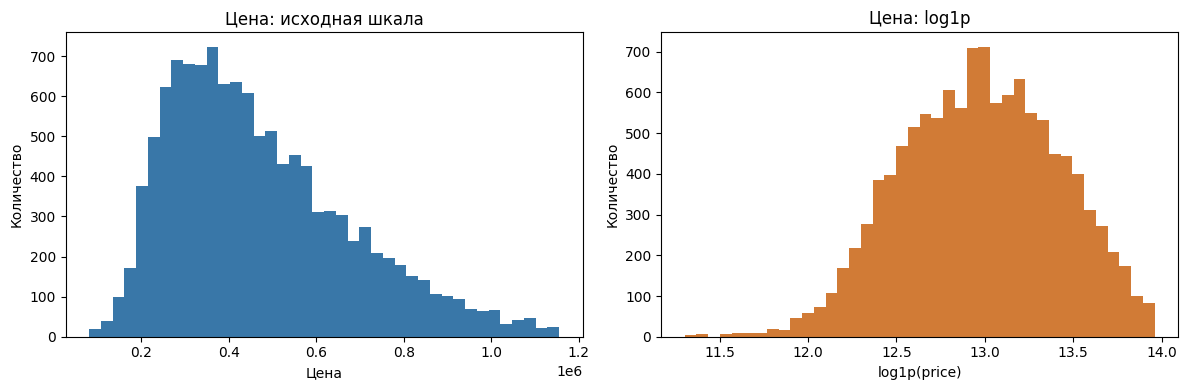

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(dev['price'], bins=40, color='#3977a8')
ax[0].set(title='Цена: исходная шкала', xlabel='Цена', ylabel='Количество')
ax[1].hist(np.log1p(dev['price']), bins=40, color='#d17b36')
ax[1].set(title='Цена: log1p', xlabel='log1p(price)', ylabel='Количество')
fig.tight_layout()
plt.show()

На исходной шкале виден длинный хвост до 1.16 млн.; после `log1p` распределение становится заметно ровнее. Это хороший повод проверить логарифмирование, но оставлю его только если оно улучшит ошибку в долларах.


Фолды собираю по уникальным датам: все продажи одного дня попадают целиком в train или test. Так ранние периоды не перемешиваются с более поздними.


In [7]:
dev_dates = dev['date'].reset_index(drop=True)
tscv = DateGroupedTimeSeriesSplit(dev_dates, n_splits=5)
fold_bounds = []
for fold, (train_idx, test_idx) in enumerate(tscv.split(dev), start=1):
    train_dates, test_dates = dev_dates.iloc[train_idx], dev_dates.iloc[test_idx]
    fold_bounds.append({
        'fold': fold, 'train_rows': len(train_idx), 'test_rows': len(test_idx),
        'train_period': f'{train_dates.min():%Y-%m-%d} — {train_dates.max():%Y-%m-%d}',
        'test_period': f'{test_dates.min():%Y-%m-%d} — {test_dates.max():%Y-%m-%d}',
    })
display(pd.DataFrame(fold_bounds))

,fold,train_rows,test_rows,train_period,test_period
0,1,2244,2220,2014-05-02 — 2014-06-25,2014-06-26 — 2014-08-18
1,2,4464,2087,2014-05-02 — 2014-08-18,2014-08-19 — 2014-10-11
2,3,6551,1940,2014-05-02 — 2014-10-11,2014-10-13 — 2014-12-07
3,4,8491,1428,2014-05-02 — 2014-12-07,2014-12-08 — 2015-02-05
4,5,9919,1864,2014-05-02 — 2015-02-05,2015-02-06 — 2015-03-31


## 2. Baseline

Сначала нужен понятный ориентир. Беру прямую цену и исходные признаки: площадь, спальни, санузлы, год/месяц, `grade` и бинарные характеристики. Числовая обработка и OneHot для `grade` живут внутри Pipeline, значит на каждом фолде обучаются только на train.


In [8]:
numeric_features = ['year', 'month', 'bedrooms', 'real_bathrooms', 'living_in_m2']
categorical_features = ['grade']
y_dev = dev['price'].reset_index(drop=True)
X_base = dev[numeric_features + bool_features + categorical_features].copy()


In [9]:
baseline_pipeline = make_pipeline(LinearRegression(), numeric_features, bool_features, categorical_features)
baseline_summary, baseline_folds = evaluate_cv(
    {'LinearRegression': (baseline_pipeline, X_base)}, y_dev, dev_dates, tscv
)
display(baseline_folds[['fold', 'train_period', 'test_period', 'mae', 'rmse', 'r2']].round(3))
display(baseline_summary.round(3))

,fold,train_period,test_period,mae,rmse,r2
0,1,2014-05-02 — 2014-06-25,2014-06-26 — 2014-08-18,115483.764,143857.544,0.520
1,2,2014-05-02 — 2014-08-18,2014-08-19 — 2014-10-11,106888.260,136119.177,0.545
2,3,2014-05-02 — 2014-10-11,2014-10-13 — 2014-12-07,113303.373,144901.614,0.503
3,4,2014-05-02 — 2014-12-07,2014-12-08 — 2015-02-05,116808.459,147710.275,0.492
4,5,2014-05-02 — 2015-02-05,2015-02-06 — 2015-03-31,118978.860,151798.081,0.483


,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025


На первых двух фолдах R² **0.52–0.55**, к пятому опускается до **0.48**. Модель даёт полезный ориентир, но качество постепенно проседает на более поздних датах — важно помнить об этом при чтении среднего R² **0.51**.


## 3. Улучшения признаков

Гипотеза: исходные размерные поля несут разные сигналы, а отношение площади к числу спален может лучше описывать просторность. Сначала сравниваю агрегат и `area_per_bedroom` на LinearRegression; затем добавляю одну строку с тем же `area_per_bedroom` на LightGBM. Это показывает, совпадает ли вывод о признаке для двух типов моделей.


In [10]:
def add_size_features(frame):
    result = frame.copy()
    bedrooms = pd.to_numeric(result['bedrooms'], errors='coerce')
    area = pd.to_numeric(result['living_in_m2'], errors='coerce')
    bathrooms = pd.to_numeric(result['real_bathrooms'], errors='coerce')
    # Ноль спален превращаю в пропуск; медиану для него возьмёт train-only imputer.
    result['area_per_bedroom'] = (area / bedrooms.where(bedrooms > 0)).where(area > 0)
    result['house_size_score'] = (bedrooms + bathrooms + area / 100).where(area > 0)
    return result

dev_fe = add_size_features(dev)
X_ratio = dev_fe[numeric_features + ['area_per_bedroom'] + bool_features + categorical_features]
agg_features = ['year', 'month', 'house_size_score']
X_aggregate = dev_fe[agg_features + bool_features + categorical_features]
feature_variants = {
    'Размерный агрегат': (make_pipeline(LinearRegression(), agg_features, bool_features, categorical_features), X_aggregate),
    'Исходные поля + area_per_bedroom': (
        make_pipeline(LinearRegression(), numeric_features + ['area_per_bedroom'], bool_features, categorical_features), X_ratio
    ),
    'LightGBM + area_per_bedroom': (
        make_pipeline(
            LGBMRegressor(n_estimators=100, random_state=42),
            numeric_features + ['area_per_bedroom'], bool_features, categorical_features,
        ), X_ratio,
    ),
}
feature_summary, feature_folds = evaluate_cv(feature_variants, y_dev, dev_dates, tscv)
display(feature_summary.round(3))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000607 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 540
[LightGBM] [Info] Number of data points in the train set: 2244, number of used features: 15
[LightGBM] [Info] Start training from score 486660.831996
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000141 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 543
[LightGBM] [Info] Number of data points in the train set: 4464, number of used features: 15
[LightGBM] [Info] Start training from score 482043.740591
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000194 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000212 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 547
[LightGBM] [Info] Number of data points in the train set: 8491, number of used features: 15
[LightGBM] [Info] Start training from score 476047.971381
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000257 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 552
[LightGBM] [Info] Number of data points in the train set: 9919, number of used features: 16
[LightGBM] [Info] Start training from score 473600.529791


,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,LightGBM + area_per_bedroom,112607.501,3727.604,143877.612,3991.192,0.516,0.013
1,Исходные поля + area_per_bedroom,114319.670,4677.157,144883.122,5841.066,0.509,0.025
2,Размерный агрегат,117972.698,4214.740,149015.068,5094.638,0.480,0.024


Агрегат проиграл исходным полям на LinearRegression: R² **0.48** против **0.51**. Для LinearRegression `area_per_bedroom` почти не меняет RMSE (144,883 против 144,877, разница 6). На LightGBM добавление отношения немного снизило MAE, но RMSE вырос с 143,579 до 143,878, а R² изменился с **0.518** до **0.516** — явного выигрыша тоже нет.


## 4. Модели и регуляризация

Сначала кратко смотрю на регуляризацию. Затем сравниваю LinearRegression и LightGBM на одинаковом `X_base`. Для LightGBM беру параметры из `baseline.ipynb`: `n_estimators=100`, `random_state=42`; ничего не подбираю.


In [11]:
regularized_variants = {
    'Ridge (alpha=1)': (make_pipeline(Ridge(alpha=1), numeric_features, bool_features, categorical_features), X_base),
    'Lasso (alpha=1)': (make_pipeline(Lasso(alpha=1, max_iter=10000), numeric_features, bool_features, categorical_features), X_base),
    'ElasticNet (alpha=1)': (
        make_pipeline(ElasticNet(alpha=1, max_iter=10000), numeric_features, bool_features, categorical_features), X_base
    ),
}
regularization_summary, _ = evaluate_cv(
    regularized_variants, y_dev, dev_dates, tscv
)
display(regularization_summary.round(3))

,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,ElasticNet (alpha=1),132119.007,4014.309,162651.774,3914.157,0.381,0.013
1,Lasso (alpha=1),114292.702,4623.365,144876.594,5780.419,0.509,0.025
2,Ridge (alpha=1),114313.128,4613.159,144866.024,5775.452,0.509,0.025


Все варианты регуляризации здесь проверены только с `alpha=1`, без подбора. Ridge и Lasso почти повторяют OLS. ElasticNet хуже в этой настройке, но результат нельзя трактовать как честное сравнение силы штрафов: цель измеряется в долларах, а масштаб и нормировка штрафа у оценивателей различаются. Подбор `alpha` и `l1_ratio` проверен отдельно в `tuning.ipynb`.


In [12]:
log_pipeline = TransformedTargetRegressor(
    regressor=make_pipeline(LinearRegression(), numeric_features, bool_features, categorical_features), func=np.log1p,
    inverse_func=np.expm1,
)
log_summary, _ = evaluate_cv(
    {'LinearRegression + log1p(price)': (log_pipeline, X_base)}, y_dev, dev_dates, tscv
)
display(log_summary.round(3))

,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,LinearRegression + log1p(price),113813.246,4911.71,146076.359,6555.929,0.5,0.031


`log1p` немного снизил MAE (113.8 тыс. против 114.3 тыс.), но повысил RMSE (146.1 тыс. против 144.9 тыс.) и снизил R² (**0.50** против **0.51**). Оставляю прямой прогноз цены: большой выигрыш по абсолютной ошибке не появился.


In [13]:
model_variants = {
    'LinearRegression': (make_pipeline(LinearRegression(), numeric_features, bool_features, categorical_features), X_base),
    'LightGBM': (
        make_pipeline(LGBMRegressor(n_estimators=100, random_state=42), numeric_features, bool_features, categorical_features), X_base
    ),
}
model_summary, model_folds = evaluate_cv(model_variants, y_dev, dev_dates, tscv)
display(model_summary.round(3))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000105 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 285
[LightGBM] [Info] Number of data points in the train set: 2244, number of used features: 14
[LightGBM] [Info] Start training from score 486660.831996
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000132 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 288
[LightGBM] [Info] Number of data points in the train set: 4464, number of used features: 14
[LightGBM] [Info] Start training from score 482043.740591
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000160 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000224 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 297
[LightGBM] [Info] Number of data points in the train set: 9919, number of used features: 15
[LightGBM] [Info] Start training from score 473600.529791


,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,LightGBM,112141.633,3451.458,143579.126,3704.690,0.518,0.011
1,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025


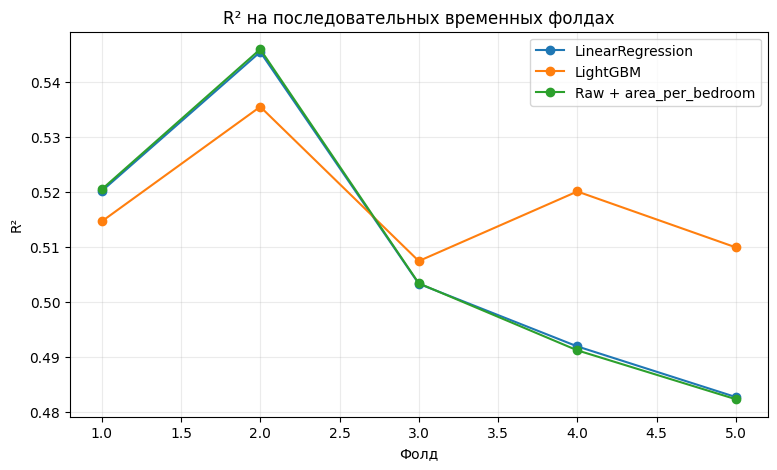

In [14]:
r2_lines = {
    'LinearRegression': baseline_folds,
    'LightGBM': model_folds[model_folds['variant'].eq('LightGBM')],
    'Raw + area_per_bedroom': feature_folds[
        feature_folds['variant'].eq('Исходные поля + area_per_bedroom')
    ],
}
fig, ax = plt.subplots(figsize=(9, 5))
for label, folds in r2_lines.items():
    ax.plot(folds['fold'], folds['r2'], marker='o', label=label)
ax.set(title='R² на последовательных временных фолдах', xlabel='Фолд', ylabel='R²')
ax.grid(alpha=0.25)
ax.legend()
plt.show()


In [15]:
model_rmse = model_folds.pivot(index='fold', columns='variant', values='rmse')
paired_lr_lgbm = model_rmse['LinearRegression'] - model_rmse['LightGBM']
paired_lr_lgbm_summary = pd.DataFrame([{'сравнение': 'LinearRegression − LightGBM',
    'разница_mean': paired_lr_lgbm.mean(), 'разница_std': paired_lr_lgbm.std(ddof=1)}])
display(paired_lr_lgbm_summary.round(3))


,сравнение,разница_mean,разница_std
0,LinearRegression − LightGBM,1298.212,2663.811


На этих пяти фолдах среднее преимущество LightGBM по RMSE составило 1 298, а стандартное отклонение парной разницы составило 2 664. Средняя разница меньше разброса парных разниц, поэтому по этим фолдам модели нельзя уверенно различить.

## 5. `quartile_zone`

Сравнение `quartile_zone` сделано на LinearRegression. В Kaggle-версии признак описан как квартильный рейтинг ZIP-зон по цене: 1 — дешевле, 4 — дороже. В нашем CSV нет исходного ZIP-кода и информации о том, на каких ценах и за какой период рассчитаны границы. Если рейтинг построен по всей выборке, он может подсматривать в цены будущих фолдов. Риск не могу проверить пересчётом, поэтому в безопасную модель признак не включаю.


In [16]:
zone_profile = dev.groupby('quartile_zone')['price'].agg(
    rows='size', mean_price='mean', median_price='median'
).reset_index()
display(zone_profile.round(0))
X_zone = X_base.assign(quartile_zone=dev['quartile_zone'].to_numpy())
zone_categories = categorical_features + ['quartile_zone']
zone_variants = {
    'Без quartile_zone': (make_pipeline(LinearRegression(), numeric_features, bool_features, categorical_features), X_base),
    'С quartile_zone': (
        make_pipeline(LinearRegression(), numeric_features, bool_features, zone_categories), X_zone
    ),
}
zone_summary, zone_folds = evaluate_cv(zone_variants, y_dev, dev_dates, tscv)
display(zone_summary.round(3))

,quartile_zone,rows,mean_price,median_price
0,1,2875,292764.0,275000.0
1,2,3405,408514.0,383000.0
2,3,3035,548190.0,525000.0
3,4,2468,678823.0,665500.0


,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Без quartile_zone,114292.543,4623.642,144877.338,5780.748,0.509,0.025
1,С quartile_zone,76706.944,2066.773,102883.425,2455.975,0.752,0.006


Средняя цена растёт от 293 тыс. в зоне 1 до 679 тыс. в зоне 4. В CV добавление `quartile_zone` поднимает R² с **0.509** до **0.752**. Такой скачок согласуется с ценовым смыслом признака, но не доказывает точный механизм утечки — безопасно использовать его всё равно нельзя.


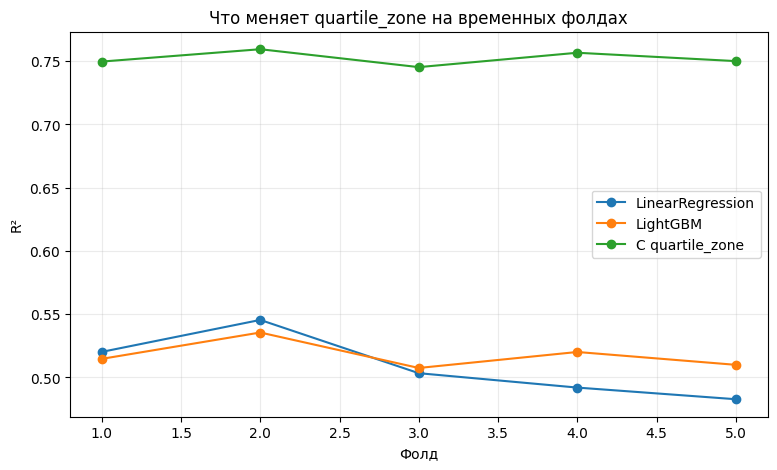

In [17]:
r2_zone_lines = {
    'LinearRegression': baseline_folds,
    'LightGBM': model_folds[model_folds['variant'].eq('LightGBM')],
    'С quartile_zone': zone_folds[zone_folds['variant'].eq('С quartile_zone')],
}
fig, ax = plt.subplots(figsize=(9, 5))
for label, folds in r2_zone_lines.items():
    ax.plot(folds['fold'], folds['r2'], marker='o', label=label)
ax.set(title='Что меняет quartile_zone на временных фолдах', xlabel='Фолд', ylabel='R²')
ax.grid(alpha=0.25)
ax.legend()
plt.show()


Без зоны R² меняется вместе с временным периодом; с `quartile_zone` он держится около **0.75** во всех пяти фолдах. Это впечатляющий, но подозрительный результат, поэтому его не использую как финальную оценку.


## 6. Поздний holdout

В этом разделе выбираю модель по минимальному среднему RMSE среди LinearRegression и LightGBM с исходными настройками, затем обучаю её на всей development-части. Holdout-цены не участвуют в сравнении или обучении; использую их только после выбора модели. Общая финальная модель проекта выбирается позже в `tuning.ipynb` по тому же правилу, уже среди настроенных вариантов.

Оговорка: прежние эксперименты оценивали модели на полном периоде; LightGBM из `baseline.ipynb` тоже мог учитывать эти месяцы. Поэтому это временная проверка, а не независимая финальная оценка.

In [18]:
selection = model_summary.sort_values(['rmse_mean', 'r2_mean']).iloc[0]
selected_model_name = selection['variant']
holdout = df.loc[holdout_mask].reset_index(drop=True)
selected_pipeline = clone(model_variants[selected_model_name][0])
X_holdout = holdout[numeric_features + bool_features + categorical_features].copy()
y_holdout = holdout['price'].reset_index(drop=True)
selected_pipeline.fit(X_base, y_dev)
holdout_prediction = selected_pipeline.predict(X_holdout)
holdout_result = pd.DataFrame([{
    'model': selected_model_name,
    'period': f'{holdout.date.min():%Y-%m-%d} — {holdout.date.max():%Y-%m-%d}',
    'rows': len(holdout),
    'mae': mean_absolute_error(y_holdout, holdout_prediction),
    'rmse': mean_squared_error(y_holdout, holdout_prediction) ** 0.5,
    'r2': r2_score(y_holdout, holdout_prediction),
}])
display(holdout_result.round(3))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000291 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 298
[LightGBM] [Info] Number of data points in the train set: 11783, number of used features: 15
[LightGBM] [Info] Start training from score 472865.887380


,model,period,rows,mae,rmse,r2
0,LightGBM,2015-04-01 — 2015-05-14,1818,119316.027,152940.335,0.453


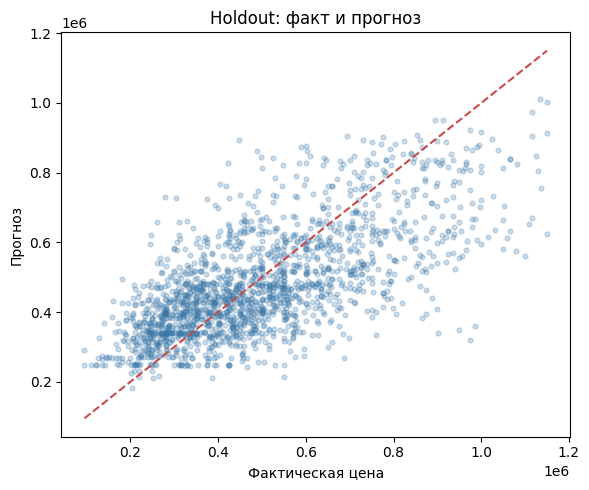

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_holdout, holdout_prediction, alpha=0.25, s=12, color='#3977a8')
low, high = y_holdout.min(), y_holdout.max()
ax.plot([low, high], [low, high], '--', color='#c64b4b')
ax.set(title='Holdout: факт и прогноз', xlabel='Фактическая цена', ylabel='Прогноз')
plt.tight_layout()
plt.show()

На графике прогнозы стягиваются к середине: недорогие дома модель иногда завышает, а самые дорогие — чаще недооценивает. Это согласуется с разницей между CV (**R² 0.51**) и holdout (**0.45**); возможны временной сдвиг или другой состав продаж, но на таком коротком периоде нельзя разделить эти причины.


## 7. Выводы

Для итоговой модели проекта использую одно правило: минимальный средний RMSE на dev-CV. По нему в `tuning.ipynb` выбран лучший LightGBM из 60 вариантов: RMSE 142 065 и R² 0,528 на CV; на holdout он получил MAE 119 145, RMSE 152 277 и R² 0,458. Оценка после подбора может быть оптимистичной, потому что тот же CV использовался для выбора параметров.

В этом ноутбуке LinearRegression и LightGBM сравнивались на одинаковых фолдах: средняя парная разница RMSE составила 1 298, std разницы 2 664, поэтому их качество здесь нельзя уверенно различить. Размерный агрегат и `area_per_bedroom` сравнивались на LinearRegression; `area_per_bedroom` дополнительно проверен на LightGBM. `quartile_zone` проверялся только на LinearRegression и исключён из-за неизвестного способа расчёта и риска утечки.

Holdout уже участвовал в ранних экспериментах, поэтому это проверка переноса во времени, а не независимая оценка. Подробные сравнения и ошибки выбранной модели приведены в `tuning.ipynb`.

In [20]:
def label_summary(summary, experiment):
    result = summary.copy()
    result.insert(0, 'experiment', experiment)
    return result

final_results = pd.concat([
    label_summary(baseline_summary, 'Baseline'),
    label_summary(feature_summary, 'Признаки'),
    label_summary(regularization_summary, 'Регуляризация'),
    label_summary(log_summary, 'Target'),
    label_summary(model_summary, 'Модель'),
    label_summary(zone_summary, 'quartile_zone'),
], ignore_index=True)
display(final_results[[
    'experiment', 'variant', 'mae_mean', 'mae_std',
    'rmse_mean', 'rmse_std', 'r2_mean', 'r2_std',
]].round(3))

,experiment,variant,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Baseline,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025
1,Признаки,LightGBM + area_per_bedroom,112607.501,3727.604,143877.612,3991.192,0.516,0.013
2,Признаки,Исходные поля + area_per_bedroom,114319.670,4677.157,144883.122,5841.066,0.509,0.025
3,Признаки,Размерный агрегат,117972.698,4214.740,149015.068,5094.638,0.480,0.024
4,Регуляризация,ElasticNet (alpha=1),132119.007,4014.309,162651.774,3914.157,0.381,0.013
5,Регуляризация,Lasso (alpha=1),114292.702,4623.365,144876.594,5780.419,0.509,0.025
6,Регуляризация,Ridge (alpha=1),114313.128,4613.159,144866.024,5775.452,0.509,0.025
7,Target,LinearRegression + log1p(price),113813.246,4911.710,146076.359,6555.929,0.500,0.031
8,Модель,LightGBM,112141.633,3451.458,143579.126,3704.690,0.518,0.011
9,Модель,LinearRegression,114292.543,4623.642,144877.338,5780.748,0.509,0.025


### Метрики LightGBM в сравнении исходных моделей


In [21]:
cv_selected = model_summary.loc[model_summary['variant'].eq(selected_model_name)].iloc[0]
final_scorecard = pd.DataFrame([
    {'набор': 'Development CV, среднее по 5 фолдам', 'модель': selected_model_name,
     'MAE': cv_selected['mae_mean'], 'MAE_std': cv_selected['mae_std'],
     'RMSE': cv_selected['rmse_mean'], 'RMSE_std': cv_selected['rmse_std'],
     'R2': cv_selected['r2_mean'], 'R2_std': cv_selected['r2_std']},
    {'набор': 'Holdout, один прогноз', 'модель': selected_model_name,
     'MAE': holdout_result.loc[0, 'mae'], 'MAE_std': np.nan,
     'RMSE': holdout_result.loc[0, 'rmse'], 'RMSE_std': np.nan,
     'R2': holdout_result.loc[0, 'r2'], 'R2_std': np.nan},
])
display(final_scorecard.round(3))


,набор,модель,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std
0,"Development CV, среднее по 5 фолдам",LightGBM,112141.633,3451.458,143579.126,3704.69,0.518,0.011
1,"Holdout, один прогноз",LightGBM,119316.027,NaN,152940.335,NaN,0.453,NaN
